<a href="https://colab.research.google.com/github/Najla-Nuricia/PemMes_244107020091_Najla/blob/main/JS10/JS10_Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Flatten, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

print("TensorFlow Version:", tf.__version__)

TensorFlow Version: 2.21.0


In [2]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

print("Shape X_train:", X_train.shape)
print("Shape y_train:", y_train.shape)
print("Shape X_test:", X_test.shape)
print("Shape y_test:", y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Shape X_train: (60000, 28, 28)
Shape y_train: (60000,)
Shape X_test: (10000, 28, 28)
Shape y_test: (10000,)


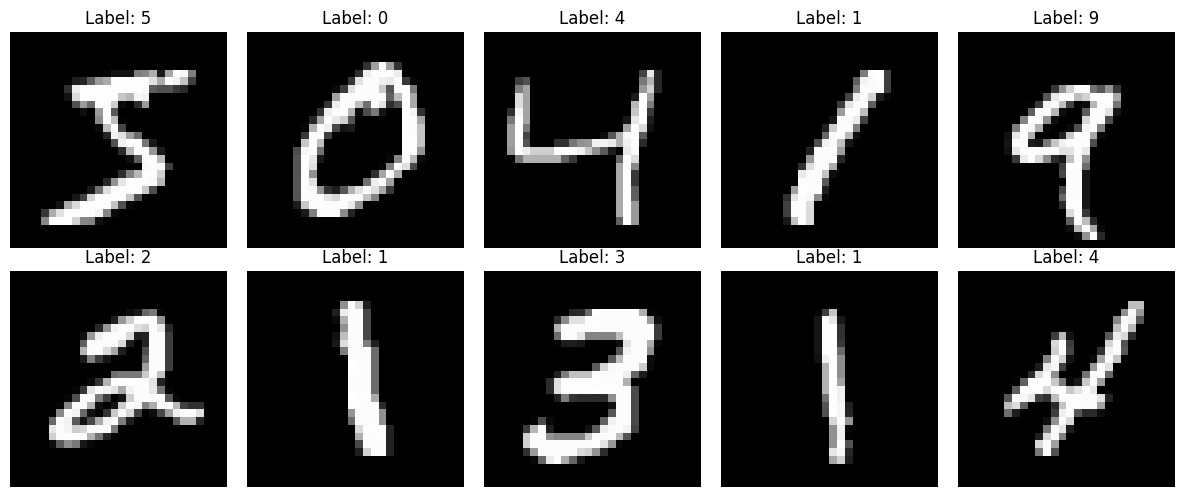

In [3]:
plt.figure(figsize=(12, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(f"Label: {y_train[i]}")
    plt.axis('off')

plt.tight_layout()
plt.show()

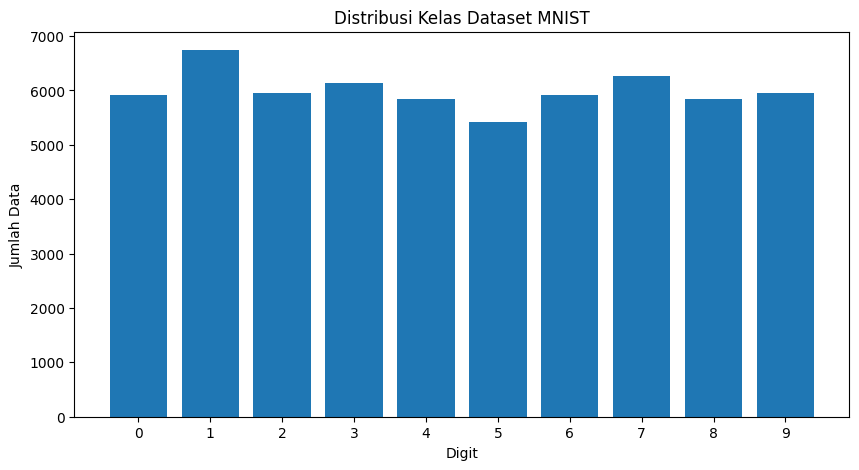

In [4]:
unique, counts = np.unique(y_train, return_counts=True)

plt.figure(figsize=(10, 5))
plt.bar(unique, counts)
plt.xlabel("Digit")
plt.ylabel("Jumlah Data")
plt.title("Distribusi Kelas Dataset MNIST")
plt.xticks(range(10))
plt.show()

In [5]:
# Normalisasi
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Flatten gambar 28x28 menjadi 784 fitur
X_train = X_train.reshape(X_train.shape[0], 784)
X_test = X_test.reshape(X_test.shape[0], 784)

print("Shape X_train setelah preprocessing:", X_train.shape)
print("Shape X_test setelah preprocessing:", X_test.shape)
print("Nilai piksel minimum:", X_train.min())
print("Nilai piksel maksimum:", X_train.max())

Shape X_train setelah preprocessing: (60000, 784)
Shape X_test setelah preprocessing: (10000, 784)
Nilai piksel minimum: 0.0
Nilai piksel maksimum: 1.0


In [6]:
model = Sequential([
    Input(shape=(784,)),

    Dense(256, activation='relu'),
    Dropout(0.2),

    Dense(128, activation='relu'),
    Dropout(0.2),

    Dense(10, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [8]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=128,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - accuracy: 0.8924 - loss: 0.3621 - val_accuracy: 0.9668 - val_loss: 0.1140
Epoch 2/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9551 - loss: 0.1503 - val_accuracy: 0.9745 - val_loss: 0.0839
Epoch 3/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 12ms/step - accuracy: 0.9665 - loss: 0.1114 - val_accuracy: 0.9770 - val_loss: 0.0769
Epoch 4/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9730 - loss: 0.0846 - val_accuracy: 0.9775 - val_loss: 0.0788
Epoch 5/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - accuracy: 0.9775 - loss: 0.0714 - val_accuracy: 0.9763 - val_loss: 0.0754
Epoch 6/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.9805 - loss: 0.0591 - val_accuracy: 0.9807 - val_loss: 0.0706
Epoch 7/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9832 - loss: 0.0509 - val_accuracy: 0.9818 - val_loss: 0.0649
Epoch 8/15
422/422 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.9861 - loss: 0.0441 - val_accu

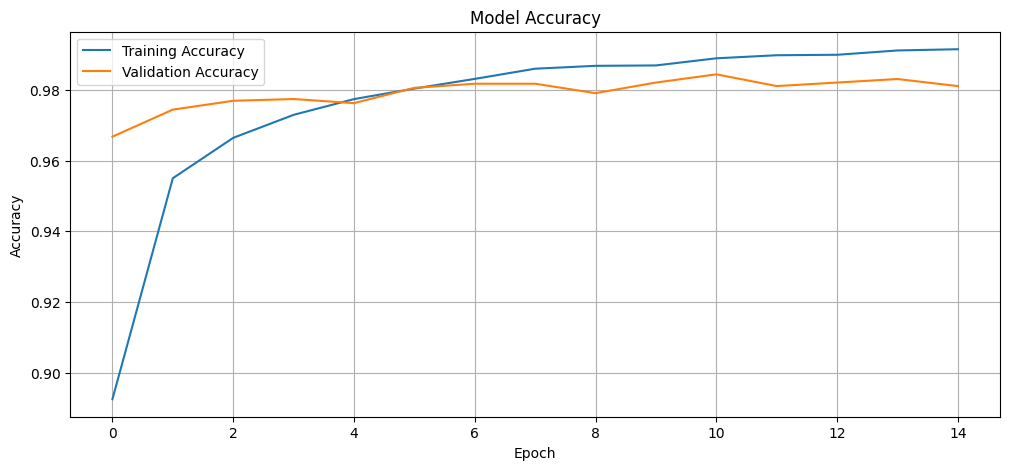

In [9]:
plt.figure(figsize=(12, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid()
plt.show()v

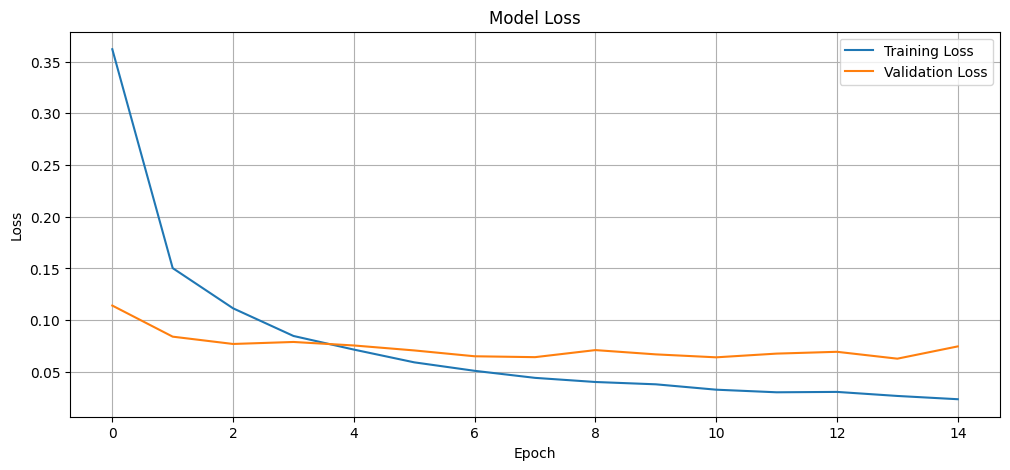

In [10]:
plt.figure(figsize=(12, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid()
plt.show()

In [11]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", test_accuracy * 100)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9818 - loss: 0.0664
Test Loss: 0.06637134402990341
Test Accuracy: 0.9818000197410583
Test Accuracy (%): 98.18000197410583


In [12]:
y_pred = model.predict(X_test)

# Mengambil kelas dengan probabilitas tertinggi
y_pred_classes = np.argmax(y_pred, axis=1)

print(classification_report(
    y_test,
    y_pred_classes,
    digits=4
))

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step
              precision    recall  f1-score   support

           0     0.9868    0.9898    0.9883       980
           1     0.9912    0.9930    0.9921      1135
           2     0.9743    0.9903    0.9822      1032
           3     0.9725    0.9792    0.9758      1010
           4     0.9837    0.9827    0.9832       982
           5     0.9841    0.9731    0.9786       892
           6     0.9854    0.9864    0.9859       958
           7     0.9776    0.9786    0.9781      1028
           8     0.9834    0.9733    0.9783       974
           9     0.9790    0.9693    0.9741      1009

    accuracy                         0.9818     10000
   macro avg     0.9818    0.9816    0.9817     10000
weighted avg     0.9818    0.9818    0.9818     10000



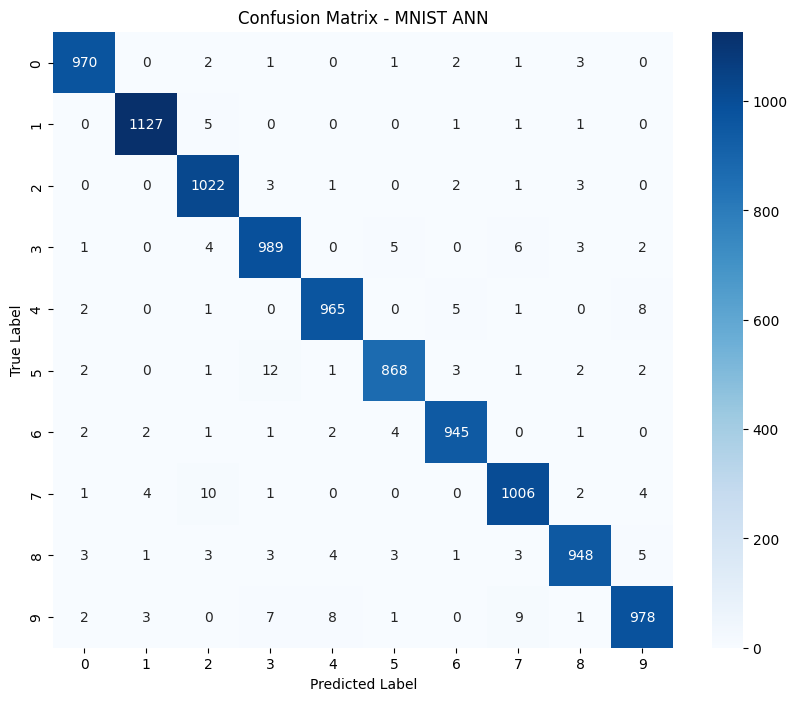

In [13]:
cm = confusion_matrix(y_test, y_pred_classes)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=range(10),
    yticklabels=range(10)
)

plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - MNIST ANN')
plt.show()

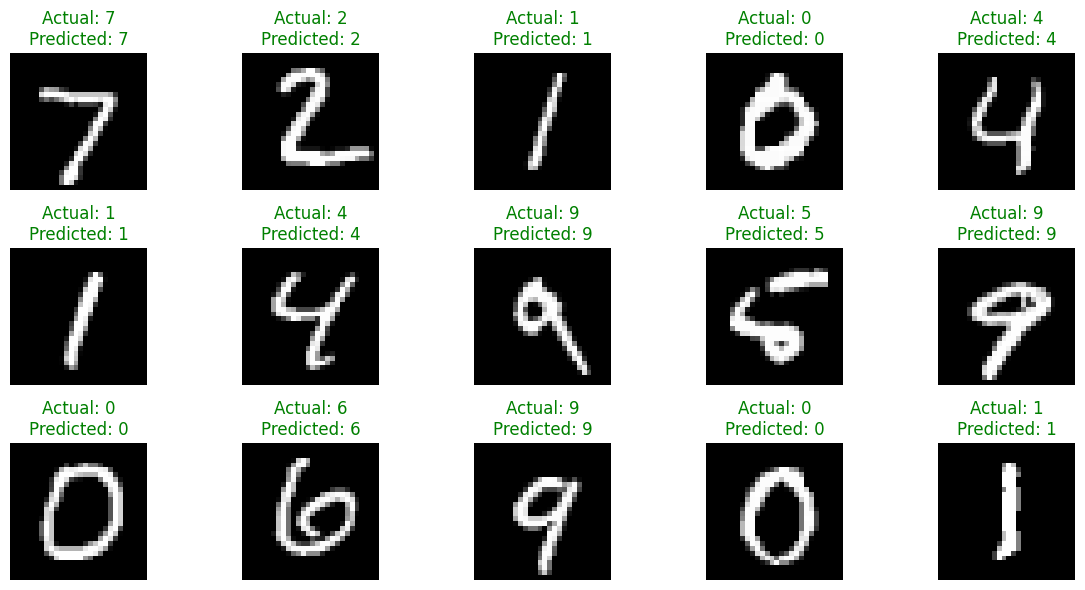

In [14]:
plt.figure(figsize=(12, 6))

for i in range(15):
    plt.subplot(3, 5, i + 1)

    plt.imshow(X_test[i].reshape(28, 28), cmap='gray')

    predicted = y_pred_classes[i]
    actual = y_test[i]

    color = 'green' if predicted == actual else 'red'

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}",
        color=color
    )

    plt.axis('off')

plt.tight_layout()
plt.show()